# Data exploration
This notebook explores the retail transaction dataset to assess data quality and identify sales patterns relevant to demand forecasting. It examines missing values, duplicate records, and potentially unrealistic values. The findings will guide the selection of an initial product with sufficient sales history and reasonably regular sales for subsequent forecasting and inventory analysis.

In [19]:
import pandas as pd 
import matplotlib.pyplot as plt 
from statsmodels.tsa.seasonal import STL
from statsmodels.graphics.tsaplots import plot_acf
from pathlib import Path


# set path to the raw data file
PROJECT_ROOT = Path.cwd().parent
raw_data_path = PROJECT_ROOT / "data/raw/online_retail_II.csv"
df = pd.read_csv(raw_data_path)

In [2]:
# First five rows

df.head()

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085.0,United Kingdom
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085.0,United Kingdom
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085.0,United Kingdom


In [6]:
# check number of rows and columns
df.shape

(1067371, 8)

In [7]:
# column names
df.columns 

Index(['Invoice', 'StockCode', 'Description', 'Quantity', 'InvoiceDate',
       'Price', 'Customer ID', 'Country'],
      dtype='str')

In [3]:
# further info
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1067371 entries, 0 to 1067370
Data columns (total 8 columns):
 #   Column       Non-Null Count    Dtype  
---  ------       --------------    -----  
 0   Invoice      1067371 non-null  str    
 1   StockCode    1067371 non-null  str    
 2   Description  1062989 non-null  str    
 3   Quantity     1067371 non-null  int64  
 4   InvoiceDate  1067371 non-null  str    
 5   Price        1067371 non-null  float64
 6   Customer ID  824364 non-null   float64
 7   Country      1067371 non-null  str    
dtypes: float64(2), int64(1), str(5)
memory usage: 65.1 MB


From the eight columns, 2 contain null values. We can confirm this in the following code chunk

In [4]:
df.isna().sum()

Invoice             0
StockCode           0
Description      4382
Quantity            0
InvoiceDate         0
Price               0
Customer ID    243007
Country             0
dtype: int64

In [13]:
# Check descriptive statistics of numerical columns
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Quantity,1067371.0,9.938898,172.705794,-80995.00,1.00,3.0,10.00,80995.0
Price,1067371.0,4.649388,123.553059,-53594.36,1.25,2.1,4.15,38970.0
Customer ID,824364.0,15324.638504,1697.464450,12346.00,13975.00,15255.0,16797.00,18287.0


Quantity and Price contain negative values, which is unrealistic for stocks data as quantity and price can't be negative. They will be investigated further along the EDA process. Outliers and extremely large values are also present given the difference between 75% percentile and the maximum values.  

In [41]:
df["Price"].quantile(0.99)

np.float64(18.0)

In [17]:
# check for duplicates
df.duplicated().sum()

np.int64(34335)

Dataset also contain a large number of duplicates

In [25]:
# for time series analysis, first typecast invoice date to date time data type
df["InvoiceDate"] = pd.to_datetime(df["InvoiceDate"])
# check data types
df.dtypes

Invoice                   str
StockCode                 str
Description               str
Quantity                int64
InvoiceDate    datetime64[us]
Price                 float64
Customer ID           float64
Country                   str
dtype: object

## Time Series Analysis
To support demand forecasting, this analysis examines trends, seasonality, possible cycles, and unexplained variation in daily sales. The variable of interest is the daily quantity sold for a selected product, after handling cancellations, returns, and non-sales records. Observed sales serve as a proxy for demand, although they may underestimate actual demand when stock is unavailable.

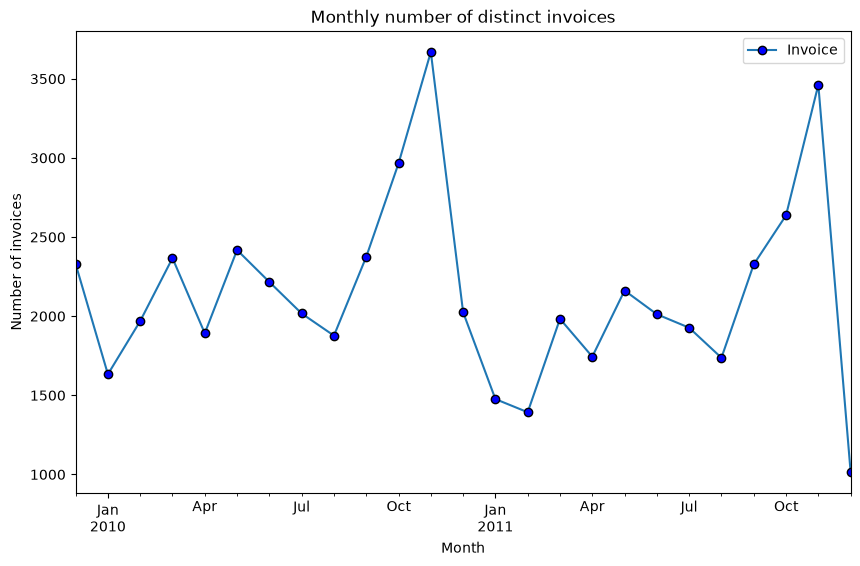

In [30]:
# plot values
ax = (
    df.set_index("InvoiceDate")
    .resample("ME")["Invoice"]
    .nunique()
    .plot(
    figsize=(10,6), 
    marker = "o",
    linestyle= "-",
    markerfacecolor = "blue",
    markeredgecolor = "black"
    )
)

ax.set(
    title="Monthly number of distinct invoices",
    xlabel = "Month",
    ylabel="Number of invoices"
)
ax.legend()
plt.show()

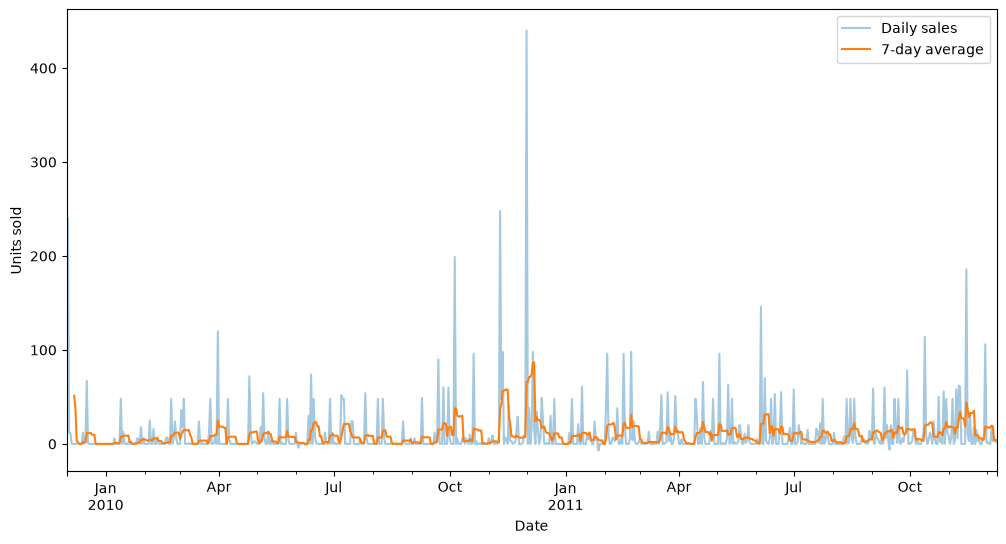

In [66]:
# for daily quantity sold for a selected product
product_id = "22041"
product_df = df.loc[df["StockCode"] == product_id]

daily_sales = (
    product_df.set_index("InvoiceDate")
    .resample("D")["Quantity"]
    .sum()
)

ax1 = daily_sales.plot(figsize=(12,6), alpha=0.4, label="Daily sales")
daily_sales.rolling(7).mean().plot(ax=ax1, label="7-day average")
ax1.set(xlabel="Date", ylabel="Units sold")
ax1.legend()

### Handling of cancellations, returns, no-sales and ambiguous records.
Flag unusual values such as negative quantities for further investigation

In [42]:
# First diagnostic subset
quantity_limit = df["Quantity"].abs().quantile(0.99)
price_limit = df["Price"].abs().quantile(0.99)
invoice = df["Invoice"].astype("string").str.strip()

flagged = df.loc[
    (df["Quantity"] <= 0) 
    | (df["Price"] <= 0) 
    | invoice.str.upper().str.startswith("C", na= False) # cancellation convention
    | (df["Quantity"].abs() > quantity_limit)
    | (df["Price"].abs() > price_limit)
].copy()

display(flagged.head(20))

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
126,489444,POST,POSTAGE,1,2009-12-01 09:55:00,141.00,12636.0,USA
173,489447,POST,POSTAGE,1,2009-12-01 10:10:00,130.00,12362.0,Belgium
178,C489449,22087,PAPER BUNTING WHITE LACE,-12,2009-12-01 10:33:00,2.95,16321.0,Australia
179,C489449,85206A,CREAM FELT EASTER EGG BASKET,-6,2009-12-01 10:33:00,1.65,16321.0,Australia
180,C489449,21895,POTTING SHED SOW 'N' GROW SET,-4,2009-12-01 10:33:00,4.25,16321.0,Australia
181,C489449,21896,POTTING SHED TWINE,-6,2009-12-01 10:33:00,2.10,16321.0,Australia
182,C489449,22083,PAPER CHAIN KIT RETRO SPOT,-12,2009-12-01 10:33:00,2.95,16321.0,Australia
183,C489449,21871,SAVE THE PLANET MUG,-12,2009-12-01 10:33:00,1.25,16321.0,Australia
184,C489449,84946,ANTIQUE SILVER TEA GLASS ETCHED,-12,2009-12-01 10:33:00,1.25,16321.0,Australia
185,C489449,84970S,HANGING HEART ZINC T-LIGHT HOLDER,-24,2009-12-01 10:33:00,0.85,16321.0,Australia


In [ ]:
# Investigate further the flagged subset
flagged.info()

<class 'pandas.DataFrame'>
Index: 43900 entries, 126 to 1067178
Data columns (total 8 columns):
 #   Column       Non-Null Count  Dtype         
---  ------       --------------  -----         
 0   Invoice      43900 non-null  str           
 1   StockCode    43900 non-null  str           
 2   Description  39518 non-null  str           
 3   Quantity     43900 non-null  int64         
 4   InvoiceDate  43900 non-null  datetime64[us]
 5   Price        43900 non-null  float64       
 6   Customer ID  29941 non-null  float64       
 7   Country      43900 non-null  str           
dtypes: datetime64[us](1), float64(2), int64(1), str(4)
memory usage: 3.0 MB


In [44]:
# Inspect the largest records directly

display(
    df.loc[df["Quantity"].abs().nlargest(20).index]
)

display(
    df.loc[df["Price"].abs().nlargest(20).index]
)

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
1065882,581483,23843,"PAPER CRAFT , LITTLE BIRDIE",80995,2011-12-09 09:15:00,2.08,16446.0,United Kingdom
1065883,C581484,23843,"PAPER CRAFT , LITTLE BIRDIE",-80995,2011-12-09 09:27:00,2.08,16446.0,United Kingdom
587080,541431,23166,MEDIUM CERAMIC TOP STORAGE JAR,74215,2011-01-18 10:01:00,1.04,12346.0,United Kingdom
587085,C541433,23166,MEDIUM CERAMIC TOP STORAGE JAR,-74215,2011-01-18 10:17:00,1.04,12346.0,United Kingdom
90857,497946,37410,BLACK AND WHITE PAISLEY FLOWER MUG,19152,2010-02-15 11:57:00,0.10,13902.0,Denmark
127166,501534,21099,SET/6 STRAWBERRY PAPER CUPS,12960,2010-03-17 13:09:00,0.10,13902.0,Denmark
127168,501534,21091,SET/6 WOODLAND PAPER PLATES,12960,2010-03-17 13:09:00,0.10,13902.0,Denmark
127169,501534,21085,SET/6 WOODLAND PAPER CUPS,12744,2010-03-17 13:09:00,0.10,13902.0,Denmark
1027583,578841,84826,ASSTD DESIGN 3D PAPER STICKERS,12540,2011-11-25 15:57:00,0.00,13256.0,United Kingdom
127167,501534,21092,SET/6 STRAWBERRY PAPER PLATES,12480,2010-03-17 13:09:00,0.10,13902.0,Denmark


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
179403,A506401,B,Adjust bad debt,1,2010-04-29 13:36:00,-53594.36,NaN,United Kingdom
276274,A516228,B,Adjust bad debt,1,2010-07-19 11:24:00,-44031.79,NaN,United Kingdom
748142,C556445,M,Manual,-1,2011-06-10 15:31:00,38970.00,15098.0,United Kingdom
403472,A528059,B,Adjust bad debt,1,2010-10-20 12:04:00,-38925.87,NaN,United Kingdom
241824,C512770,M,Manual,-1,2010-06-17 16:52:00,25111.09,17399.0,United Kingdom
241827,512771,M,Manual,1,2010-06-17 16:53:00,25111.09,NaN,United Kingdom
320581,C520667,BANK CHARGES,Bank Charges,-1,2010-08-27 13:42:00,18910.69,NaN,United Kingdom
1050063,C580605,AMAZONFEE,AMAZON FEE,-1,2011-12-05 11:36:00,17836.46,NaN,United Kingdom
569163,C540117,AMAZONFEE,AMAZON FEE,-1,2011-01-05 09:55:00,16888.02,NaN,United Kingdom
569164,C540118,AMAZONFEE,AMAZON FEE,-1,2011-01-05 09:57:00,16453.71,NaN,United Kingdom


#### Interpretation of the first diagnosis
The 2 largest positive quantities have matching negative counterparts on C invoices. These are potential cancelled sales. This applies for other transactions with this behaviour. If the product, customer, unit price and dates match, they can be excluded from the dataset. 

Other large quantities have plausible descriptions and low prices. They might be retained as they may represent legitimate bulk purchases. 

Zero price records with missing descriptions and customer identifiers represent incomplete records that would need further adjustments. 

Bad-debt adjustments and Amazon fees will be excluded from the product-sales dataset because they do not represent product demand. On the other hand, Manual-describet records require further inspection before they can also be removed or kept. 

#### Further investigation of flagged transactions.
Anomalous values require further investigation before deciding on whether to remove or keep them. If kept, there should be a way to represent them.

In [45]:
# extreme quantities
extreme_rows = df.loc[df["Quantity"].abs() == 80995]
display(extreme_rows)

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
1065882,581483,23843,"PAPER CRAFT , LITTLE BIRDIE",80995,2011-12-09 09:15:00,2.08,16446.0,United Kingdom
1065883,C581484,23843,"PAPER CRAFT , LITTLE BIRDIE",-80995,2011-12-09 09:27:00,2.08,16446.0,United Kingdom


This was a cancellation. All other entries are identical.

In [ ]:
# Exclude non product codes
non_product_codes = ["B", "BANK CHARGES", "AMAZONFEE", "M"]

non_sales_mask = (
    df["StockCode"].astype("string").str.strip().isin(non_product_codes)
)

product_transactions = df.loc[~non_sales_mask].copy()

In [50]:
# Investigate duplicates
duplicates = df.loc[df.duplicated(keep=False)]
display(duplicates.sort_values(["InvoiceDate", "Invoice"]))

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
362,489517,21913,VINTAGE SEASIDE JIGSAW PUZZLES,1,2009-12-01 11:34:00,3.75,16329.0,United Kingdom
363,489517,21912,VINTAGE SNAKES & LADDERS,1,2009-12-01 11:34:00,3.75,16329.0,United Kingdom
365,489517,21821,GLITTER STAR GARLAND WITH BELLS,1,2009-12-01 11:34:00,3.75,16329.0,United Kingdom
367,489517,22319,HAIRCLIPS FORTIES FABRIC ASSORTED,12,2009-12-01 11:34:00,0.65,16329.0,United Kingdom
368,489517,22130,PARTY CONE CHRISTMAS DECORATION,6,2009-12-01 11:34:00,0.85,16329.0,United Kingdom
...,...,...,...,...,...,...,...,...
1067136,581538,22068,BLACK PIRATE TREASURE CHEST,1,2011-12-09 11:34:00,0.39,14446.0,United Kingdom
1067150,581538,23318,BOX OF 6 MINI VINTAGE CRACKERS,1,2011-12-09 11:34:00,2.49,14446.0,United Kingdom
1067153,581538,22992,REVOLVER WOODEN RULER,1,2011-12-09 11:34:00,1.95,14446.0,United Kingdom
1067160,581538,22694,WICKER STAR,1,2011-12-09 11:34:00,2.10,14446.0,United Kingdom


In [48]:
display(
    df.loc[
        (df["Invoice"] == "489517")
        & (df["StockCode"] == "21913")
    ]
)

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
362,489517,21913,VINTAGE SEASIDE JIGSAW PUZZLES,1,2009-12-01 11:34:00,3.75,16329.0,United Kingdom
385,489517,21913,VINTAGE SEASIDE JIGSAW PUZZLES,1,2009-12-01 11:34:00,3.75,16329.0,United Kingdom


In [51]:
print("Potential rows to remove:", df.duplicated().sum())


Potential rows to remove: 34335


In [54]:
# After first diagnostic, remove exact duplicates and non-product entries, treat cancellations and returns as reverse records and investigate remaining negative quantities.
product_transactions = product_transactions.drop_duplicates().copy()

# reverse orders rule: invoice starts with a C and quantity is negative

is_c_invoice = (
    product_transactions["Invoice"].astype("string")
    .str.strip()
    .str.upper()
    .str.startswith("C", na=False)
)

is_negative = product_transactions["Quantity"] < 0

recorded_reversals = product_transactions.loc[is_c_invoice & is_negative].copy()

other_negative_records = product_transactions.loc[~is_c_invoice & is_negative].copy()

# check for potential exceptions to the expected cancellation convention

c_invoice_non_negative = product_transactions.loc[
    is_c_invoice & (product_transactions["Quantity"] >= 0)
].copy()

In [59]:
other_negative_records.describe().T

,count,mean,min,25%,50%,75%,max,std
Quantity,3393.0,-167.790746,-9600.0,-82.0,-26.0,-8.0,-1.0,679.125809
InvoiceDate,3393,2010-10-19 05:23:32.608311,2009-12-01 10:52:00,2010-03-26 14:38:00,2010-09-24 16:13:00,2011-04-20 12:09:00,2011-12-08 15:24:00,NaN
Price,3393.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
Customer ID,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [57]:
c_invoice_non_negative.info()

<class 'pandas.DataFrame'>
Index: 0 entries
Data columns (total 8 columns):
 #   Column       Non-Null Count  Dtype         
---  ------       --------------  -----         
 0   Invoice      0 non-null      str           
 1   StockCode    0 non-null      str           
 2   Description  0 non-null      str           
 3   Quantity     0 non-null      int64         
 4   InvoiceDate  0 non-null      datetime64[us]
 5   Price        0 non-null      float64       
 6   Customer ID  0 non-null      float64       
 7   Country      0 non-null      str           
dtypes: datetime64[us](1), float64(2), int64(1), str(4)
memory usage: 0.0 bytes


In [ ]:
# Further investigation on the remaining negative records without a C prefix
# let's start by summarizing their descriptions
display(
    other_negative_records["Description"]
    .fillna("[missing description]")
    .value_counts()
    .head(30)
)

Description
[missing description]     2633
check                      121
damages                     83
?                           81
damaged                     78
missing                     27
sold as set on dotcom       20
Damaged                     17
smashed                      9
thrown away                  9
Unsaleable, destroyed.       9
dotcom                       8
damages?                     7
??                           7
crushed                      6
given away                   6
MIA                          5
Damages                      5
counted                      5
checked                      5
wet damaged                  5
ebay                         5
ebay sales                   4
No Stock                     3
Dotcom                       3
broken                       3
CHECK                        3
wet pallet                   3
lost                         2
wet                          2
Name: count, dtype: int64

In [61]:
# Let's examine how frequently they have zero prices or missing customer identifiers
print("Zero price:", other_negative_records["Price"].eq(0).sum())
print("Missing customer:", other_negative_records["Customer ID"].isna().sum())

Zero price: 3393
Missing customer: 3393


In [62]:
# cross tabulate missing descriptions against zero prices and missing customer IDs

display(pd.crosstab(
    other_negative_records["Description"].isna(),
    [
        other_negative_records["Price"].eq(0),
        other_negative_records["Customer ID"].isna(),
    ],
    rownames=["Missing description"],
    colnames=["Zero price", "Missing customer"],
))

Zero price,True
Missing customer,True
Missing description,
False,760
True,2633


Negative-quantity records without a cancellation invoice prefix are excluded from the product-sales dataset. Their descriptions suggest stock losses, inventory adjustments, or other stock movements, while many lack sufficient information for reliable classification. These records are retained separately for audit purposes.

In [63]:
# Apply all exclusion rules to find a clean df for the project

candidate_sales = df.drop_duplicates().copy()

invoice = (
    candidate_sales["Invoice"].astype("string")
    .str.strip().str.upper()
)

stock_code = (
    candidate_sales["StockCode"].astype("string").str.strip()
)

non_product_codes = ["B", "BANK CHARGES", "AMAZONFEE", "M"]

exclude = (
    stock_code.isin(non_product_codes)
    | invoice.str.startswith("C", na=False)
    | candidate_sales["Quantity"].lt(0)
)

candidate_sales = candidate_sales.loc[~exclude].copy()



In [64]:
# apply further filters to handle zero price and quantity records, negative price and voided purchases

invoice = candidate_sales["Invoice"].astype("string").str.strip()
stock_code = candidate_sales["StockCode"].astype("string").str.strip()

known_voided_sales = (
    (invoice.eq("581483") & stock_code.eq("23843"))
    | (invoice.eq("541431") & stock_code.eq("23166"))
)

clean_df = candidate_sales.loc[
    candidate_sales["Quantity"].gt(0)
    & candidate_sales["Price"].gt(0)
    & ~known_voided_sales
].copy()

Daily quantities from positive, paid product transactions, excluding identified voided purchases. Subsequent returns are recorded separately, and unresolved reversals are not used to retrospectively alter sales.

#### Plots of daily sales of selected product, rolling averages, weekday patterns and decomposition



In [67]:
selected_code = "22041"  # Replace with the selected StockCode

product_df = clean_df.loc[
    clean_df["StockCode"].astype("string").eq(selected_code)
].copy()

product_df["InvoiceDate"] = pd.to_datetime(product_df["InvoiceDate"])

if product_df.empty:
    raise ValueError("No sales found for the selected product.")

daily_sales = (
    product_df.set_index("InvoiceDate")["Quantity"]
              .sort_index()
              .resample("D")
              .sum()
)

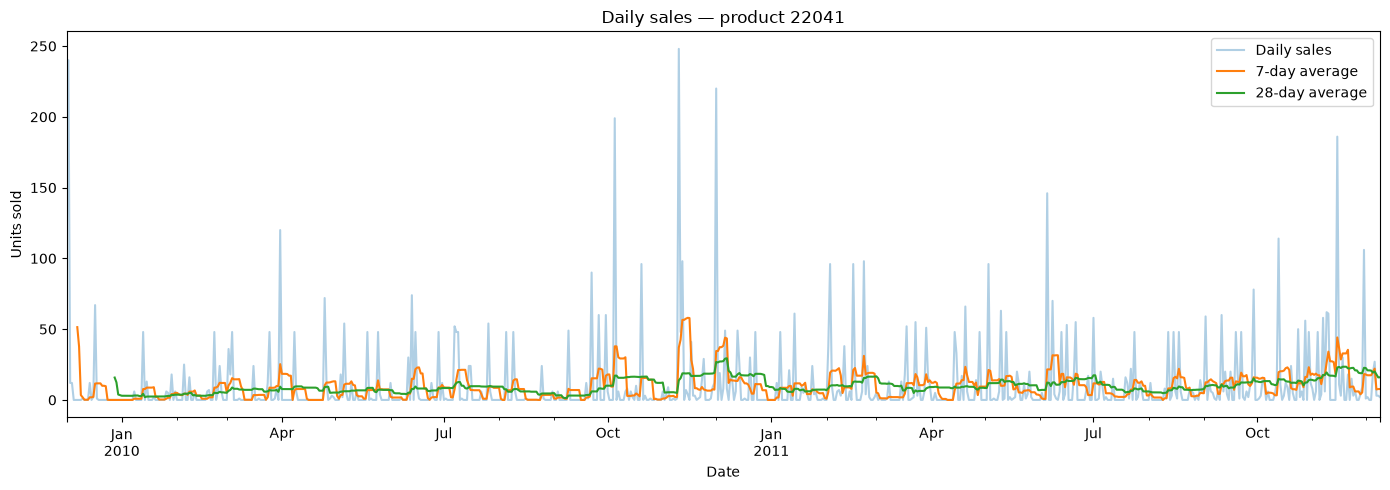

In [68]:
# Daily sales and rolling averages

fig, ax = plt.subplots(figsize=(14, 5))

daily_sales.plot(ax=ax, alpha=0.35, label="Daily sales")
daily_sales.rolling(7).mean().plot(ax=ax, label="7-day average")
daily_sales.rolling(28).mean().plot(ax=ax, label="28-day average")

ax.set(
    title=f"Daily sales — product {selected_code}",
    xlabel="Date",
    ylabel="Units sold",
)
ax.legend()
plt.tight_layout()
plt.show()

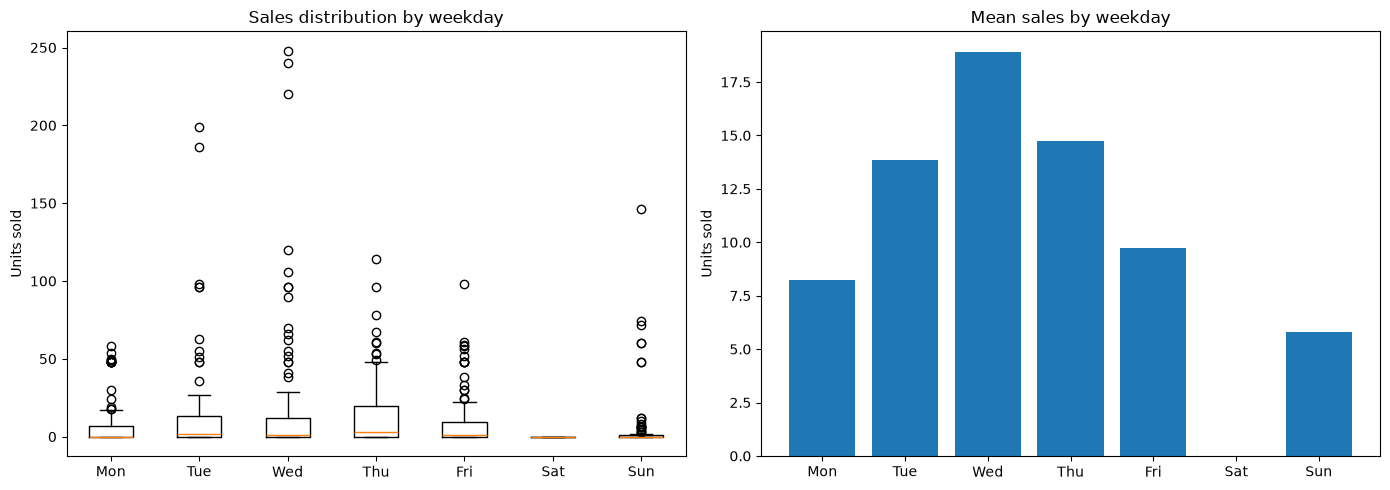

In [69]:
# Weekday patterns

weekday_df = daily_sales.rename("Sales").to_frame()
weekday_df["Weekday"] = weekday_df.index.dayofweek

labels = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
groups = [
    weekday_df.loc[weekday_df["Weekday"].eq(day), "Sales"].to_numpy()
    for day in range(7)
]

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].boxplot(groups)
axes[0].set_xticks(range(1, 8))
axes[0].set_xticklabels(labels)
axes[0].set(title="Sales distribution by weekday", ylabel="Units sold")

means = weekday_df.groupby("Weekday")["Sales"].mean().reindex(range(7))
axes[1].bar(labels, means)
axes[1].set(title="Mean sales by weekday", ylabel="Units sold")

plt.tight_layout()
plt.show()

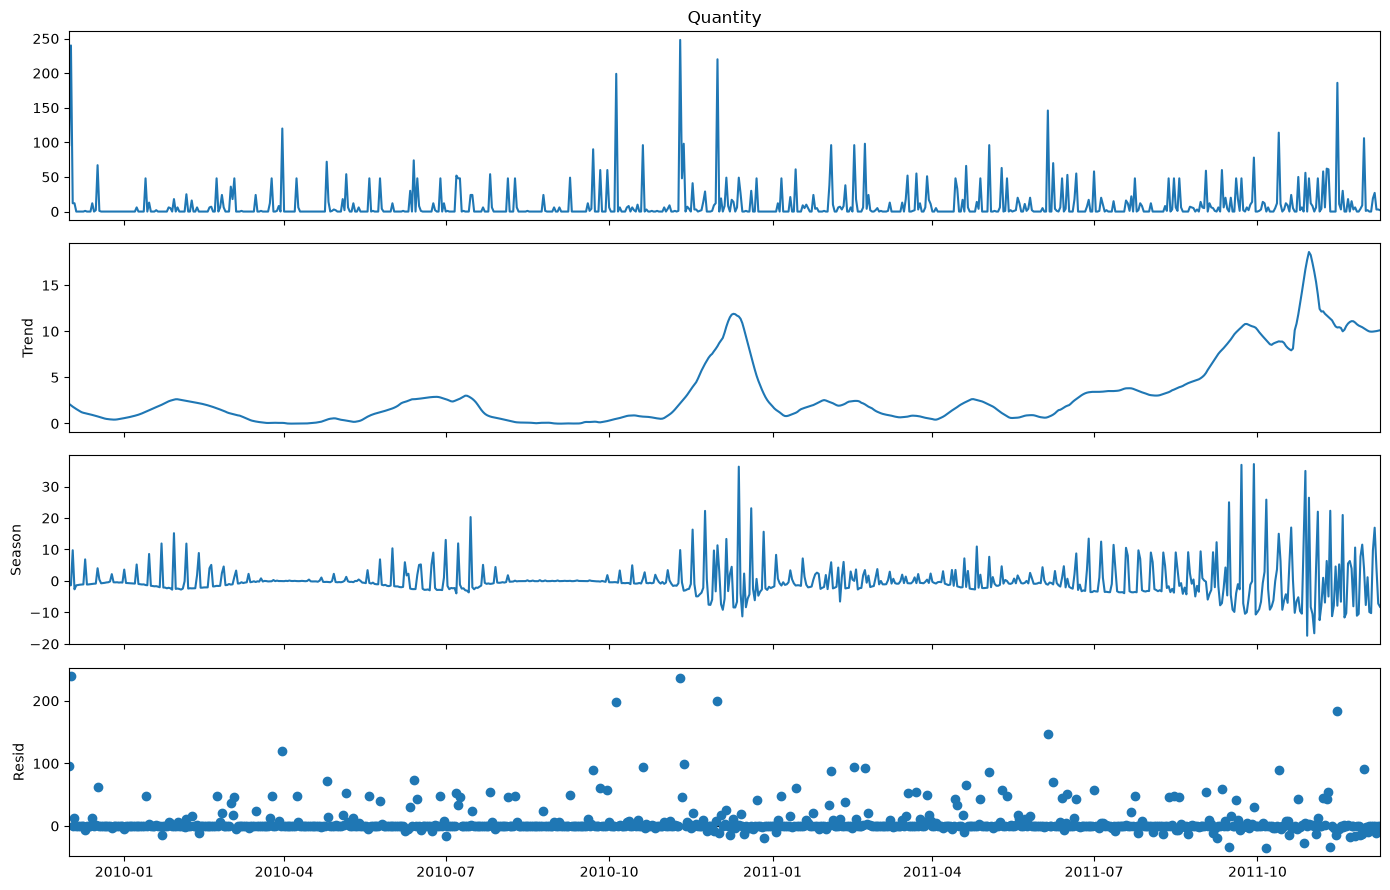

In [70]:
# Weekly STL decomposition

if len(daily_sales) < 28:
    raise ValueError("Use at least four weeks for this initial weekly analysis.")

decomposition = STL(
    daily_sales,
    period=7,
    robust=True,
).fit()

fig = decomposition.plot()
fig.set_size_inches(14, 9)
plt.tight_layout()
plt.show()